# Flat vs hierarchical planning

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/comparisons/flat_vs_hierarchical.ipynb)

Does a second, slower level help a world model plan far ahead? Three models learn PLDM's Two-Rooms from the same pixels:
- **LeWM**: one level, planned with CEM over 20 steps;
- **[HWM](../action/hwm.ipynb)**: LeWM plus a level that predicts waypoints 4 steps apart from macro-actions, planned top-down with CEM;
- **[H-JEPA](../action/hjepa.ipynb)**: two JEPA levels trained together end to end, planned top-down by gradient descent, as in its paper.

The tasks put the goal in the same room (short) or in the other room (long: the way goes through the door).

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.models import HJEPA, HWM, LeWM
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM, GradientPlanner, HierarchicalPlanner
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Data
A point wanders through two rooms joined by a door. Windows of 13 frames hold 4 waypoints, one every 4 steps.

In [3]:
data = TwoRooms(batch_size=1024, device=device).collect(65, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=13), batch_size=128, shuffle=True, drop_last=True)

## Three models, one low level
Each model's low level is the same small LeWM, trained from scratch.

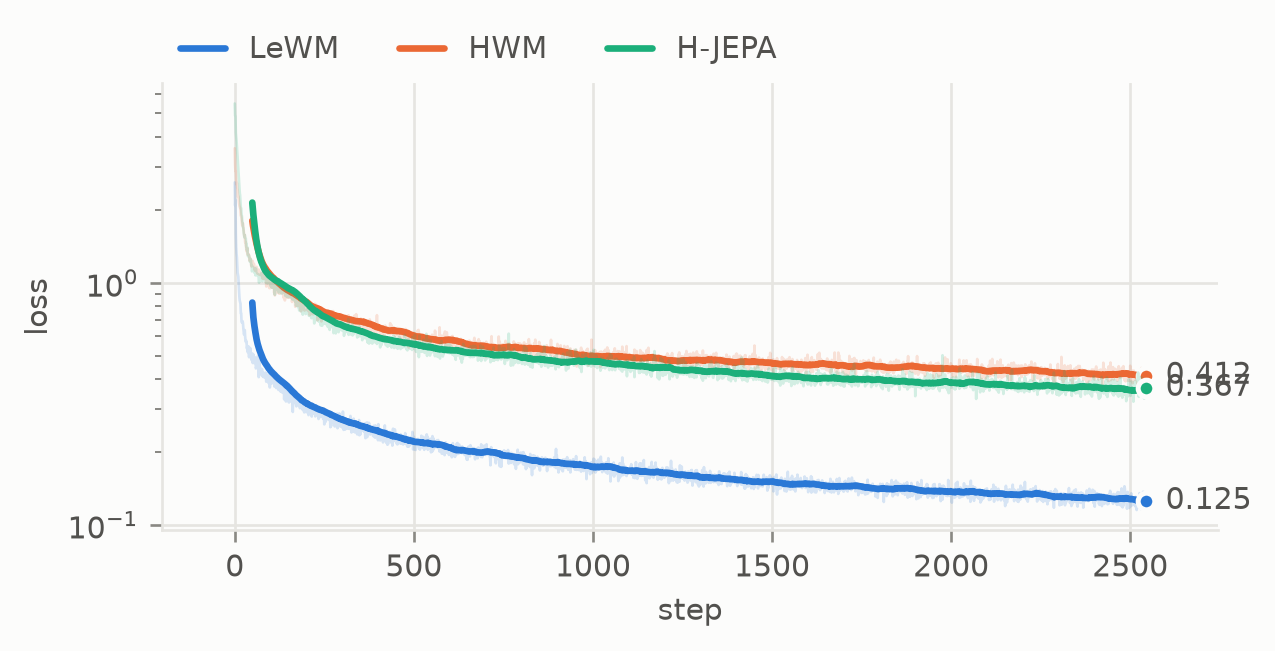

In [4]:
def lewm():
    encoder = CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4)
    return LeWM(encoder, action_dim=2, embed_dim=128, history=3, depth=4, num_heads=4, head_dim=32, mlp_dim=512, proj_dim=512, lamb=0.05)


levels = dict(stride=4, embed_dim=128, history=3, depth=4, num_heads=4, head_dim=32, mlp_dim=512)
models = {
    "LeWM": lewm(),
    "HWM": HWM(lewm(), action_dim=2, macro_dim=8, **levels),
    "H-JEPA": HJEPA(lewm(), macro_dim=4, encoder_dim=256, **levels),
}
logs = {name: fit(model.to(device), loader, epochs=6)["loss"] for name, model in models.items()}
plots.curves(logs, smooth=50)

## Planners
Every planner looks 20 steps ahead and replans after every step. The hierarchical ones plan 5 waypoints toward the goal, then 4 actions toward the first waypoint.

In [5]:
planners = {
    "LeWM": CEM(horizon=20, action_dim=2, num_samples=300, num_elites=30, bounds=(-1, 1)),
    "HWM": HierarchicalPlanner(
        CEM(horizon=5, action_dim=8, num_samples=300, num_elites=30, bounds=(-2, 2)),
        CEM(horizon=4, action_dim=2, num_samples=256, num_elites=32, iterations=6, bounds=(-1, 1)),
    ),
    "H-JEPA": HierarchicalPlanner(
        GradientPlanner(horizon=5, action_dim=4, num_samples=32, iterations=30, lr=0.1, bounds=(-2, 2)),
        GradientPlanner(horizon=4, action_dim=2, num_samples=16, iterations=30, lr=0.1, bounds=(-1, 1)),
    ),
}

## Short and long tasks
64 tasks of each kind, 60 steps each; an episode succeeds when it comes within 0.1 of the goal at any step.

In [6]:
env = TwoRooms(batch_size=64, device=device)
results = {}
for task, same_room in [("same room", True), ("other room", False)]:
    start, goal = env.tasks(torch.Generator().manual_seed(1), same_room=same_room)
    policies = {name: evaluation.goal_policy(models[name], planners[name], env.render(goal)) for name in models}
    results[task] = evaluation.goal_reaching(env, policies, start, goal, steps=60, success="reached")
    print(f"== {task}\n{results[task]}")

== same room
                  success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM       58% [46%, 69%]      58%    15.9           0.189     0.324   0.107       0.423   2.98e+04
HWM        41% [29%, 53%]      41%    8.69           0.238     0.145   0.114       0.403   9.36e+03
H-JEPA     78% [67%, 86%]      78%    19.3           0.188     0.266  0.0576        1.18   1.02e+04


== other room
                  success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM       28% [19%, 40%]      28%    30.4            0.54     0.107  0.0854        0.42   2.98e+04
HWM          9% [4%, 19%]       9%      27           0.496    0.0843  0.0476       0.381   9.37e+03
H-JEPA     67% [55%, 77%]      67%    32.7           0.225     0.611  0.0974        1.17   1.02e+04


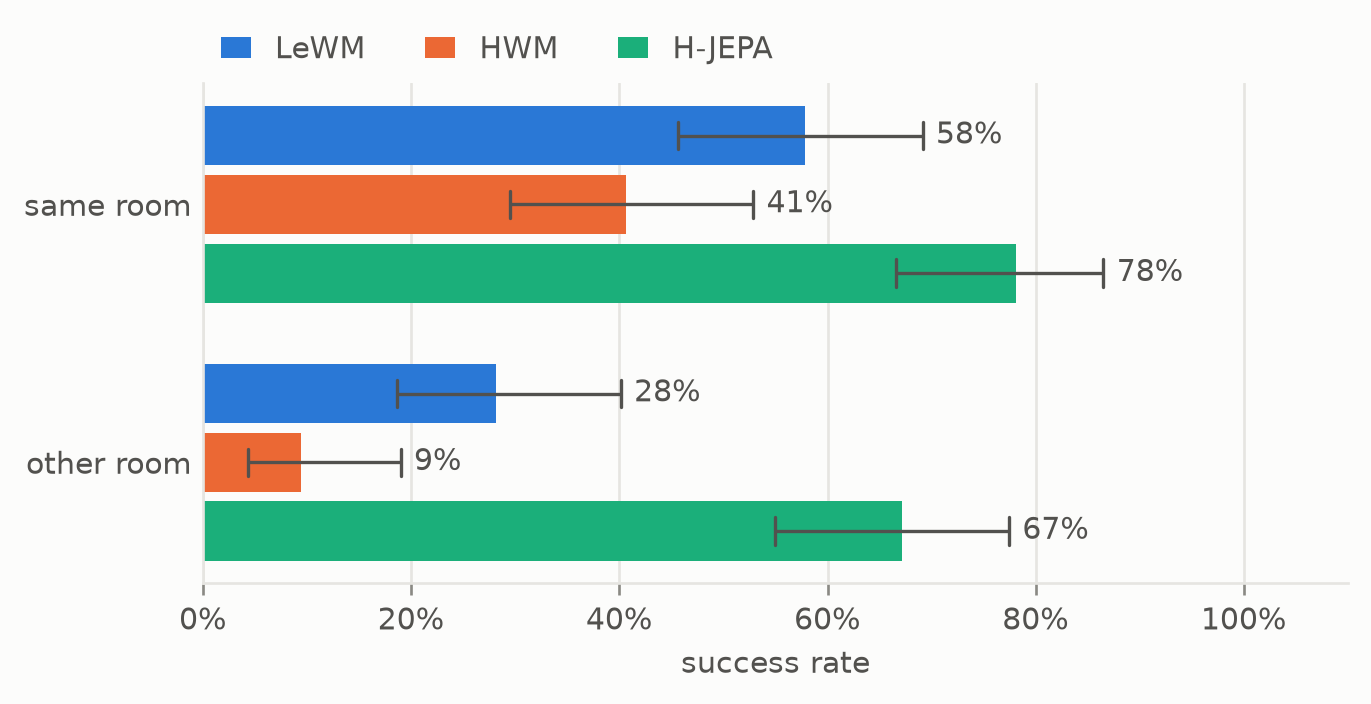

In [7]:
plots.bars({task: r.intervals() for task, r in results.items()}, xlabel="success rate")

Paths toward goals in the other room, one row per model; the darker, the later:

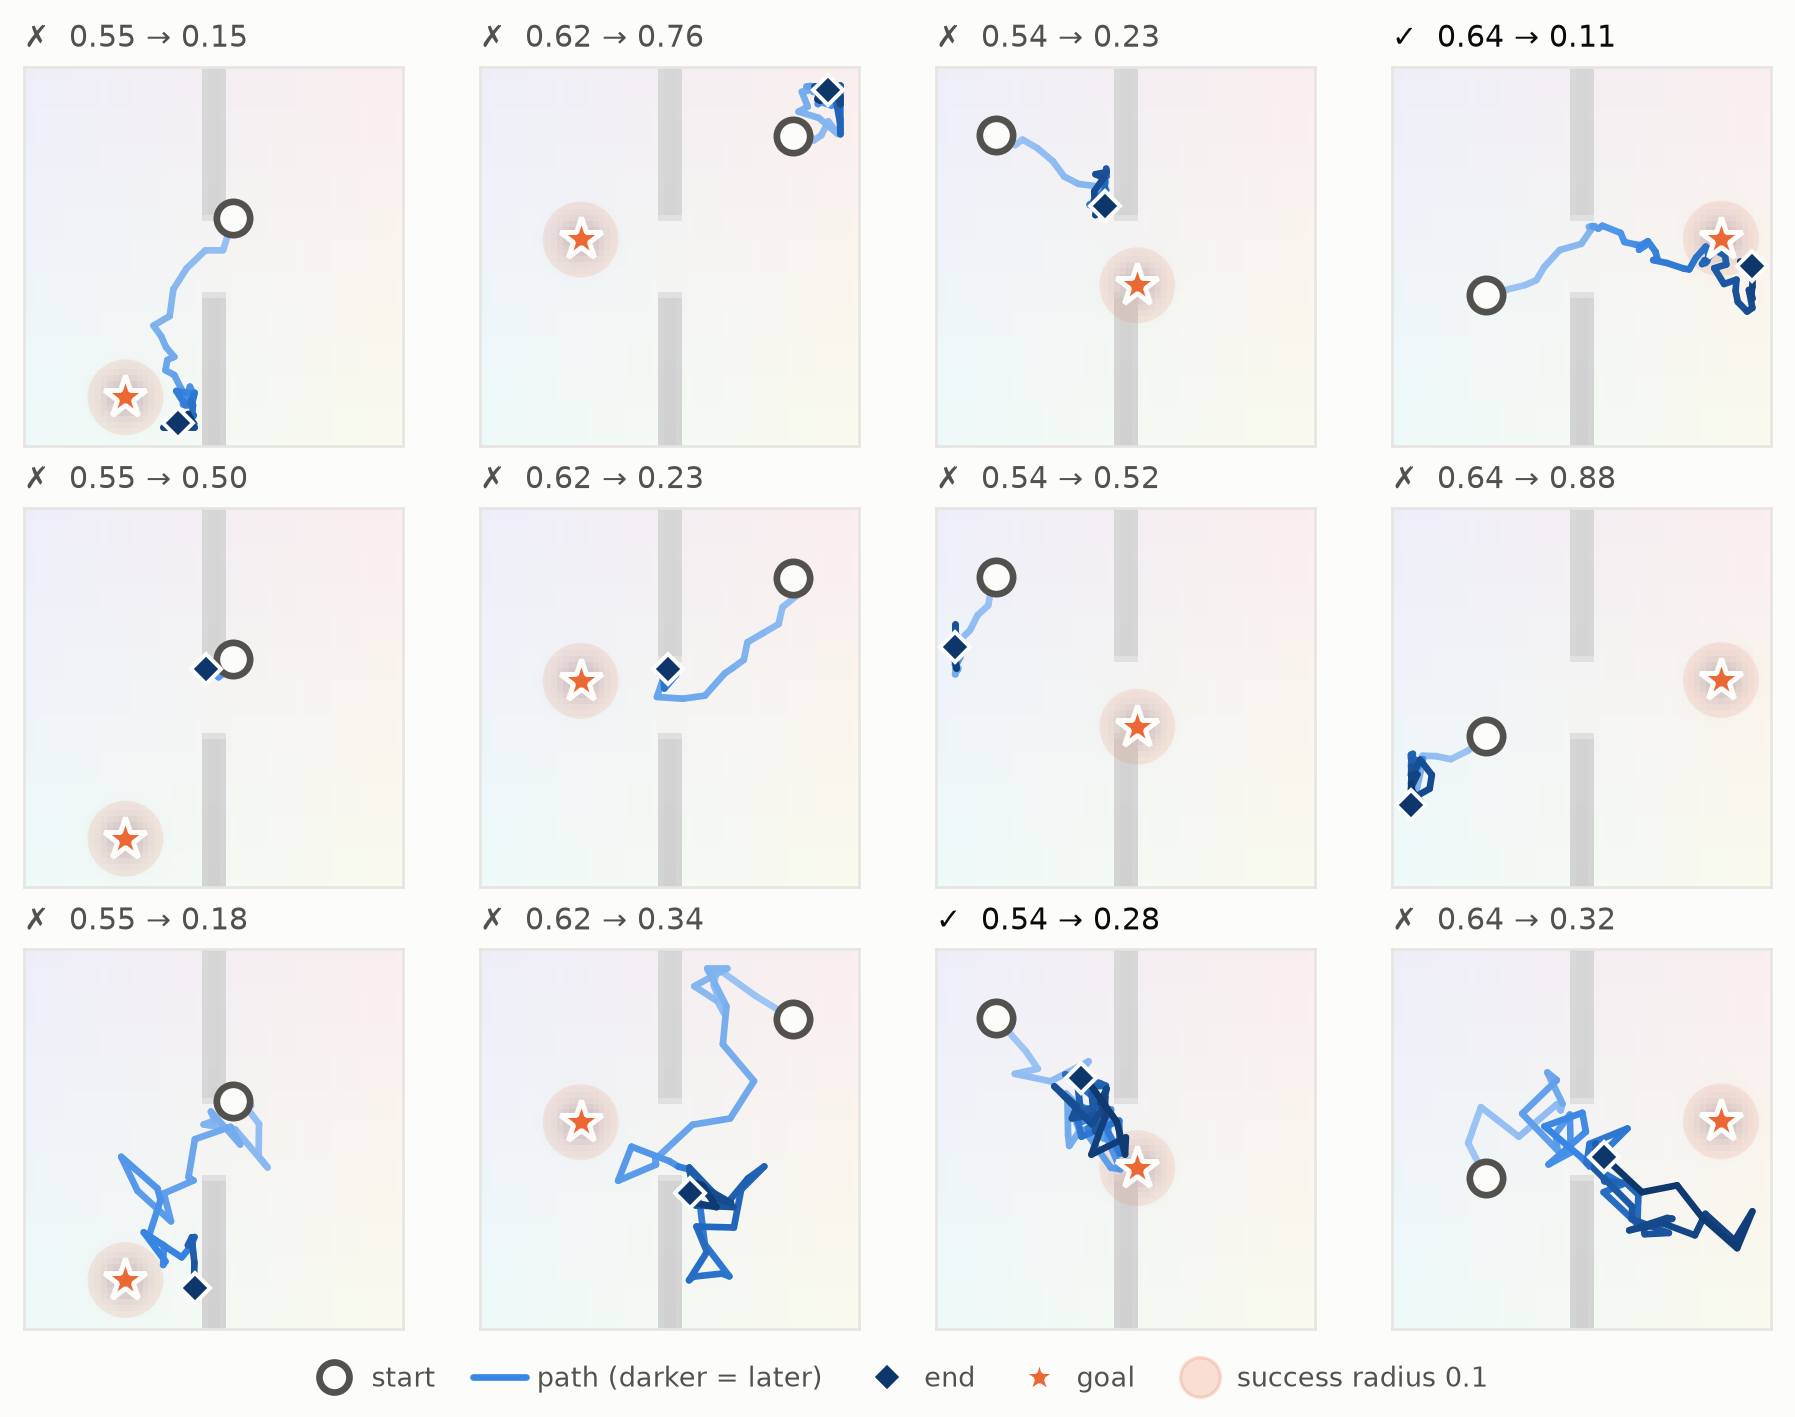

In [8]:
r = results["other room"]
plots.trajectories(
    torch.cat([r.paths[name][:4] for name in models]),
    r.goals[:4].repeat(3, 1),
    radius=env.radius,
    background=env.render(r.goals[:4]).repeat(3, 1, 1, 1),
    success=torch.cat([r.success[name][:4] for name in models]),
)

## Summary
In the same room, a straight line reaches the goal and one level is enough. In the other room the way leads away from the goal first, through the door, which a single level searching 20 actions rarely finds; the waypoint level searches 5 macro-actions over the same span. The table above shows how much that helps here, and the planning time it costs (`ms / step`).